# Image Classification with PyTorch: MLP vs CNN

In this notebook you will design, train and evaluate neural networks capable of classifying images. The dataset has two parts: 'train' and 'val'. The 'val' set will be split into an additional 'test' set to evaluate the generalization properties of your networks. Inspect the 'train' and 'val' sets so that you are familiar with their structure and content.

## Import necessary libraries

In the cell below you should import the libraries/packages required to run your code; only the ones that are actually used should be imported.
The imported libraries should be updated gradually as you progress through the required tasks.

In [1]:
import numpy as np
# update as needed
import torch
import torch.optim as optim
import torch.nn as nn

from torch.utils.data import DataLoader, random_split
from torchvision.transforms import Compose, ToTensor, ToPILImage, Resize
from torchvision.datasets import ImageFolder

import matplotlib.pyplot as plt
%matplotlib inline

from torchinfo import summary

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


## Prepare the datasets for model training and testing

Define train and validation transforms that will resize images to 65x65 size and convert them to torch tensors.

In [2]:
train_transform = Compose([Resize((65,65)),ToTensor()])
val_transform = Compose([Resize((65,65)),ToTensor()])

Create 'train' and 'val' ImageFolders from the train and val sets, resp.
Pass the transforms you created above to the ImageFolder constructor.

In [3]:
train = ImageFolder(root='train',transform=train_transform)
val = ImageFolder(root='val',transform=val_transform)

Assign 40% of the validation set to test set using the <code>random_split</code> function. Set the seed in <code>random_split</code> for 
reproducibility of your results.

In [4]:
gen = torch.Generator().manual_seed(42)
val, test = random_split(val,[0.6,0.4],generator=gen)

Sanity check: display the length of the 'train', 'val' and 'test' set; it should be 2400, 720, 480, respectively.

In [5]:
len(train),len(val),len(test)

(2400, 720, 480)

Inspect automatic labelling based on image locations.

In [6]:
class_idx = train.class_to_idx
class_idx 

{'n02102040': 0,
 'n03000684': 1,
 'n03028079': 2,
 'n03417042': 3,
 'n03445777': 4,
 'n03888257': 5}

Select one image from the validation set and display it on screen (as a single channel, graylevel image). You may see for example, a truck like the one below.

<img align = "left" src="images/im_example_single_channel.png" width="20%"> 

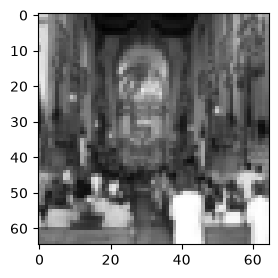

In [7]:
# your image selection
img,lab = val[100]
fig, _ = plt.subplots(figsize=(3, 3))
plt.imshow(ToPILImage()(img[0,:,:]),cmap='gray')
plt.grid(False)


Build the DataLoaders. Remember that only the train loader should shuffle the images.

In [8]:
batch_size = 64
torch.manual_seed(1)
train_loader = DataLoader(train, batch_size, shuffle=True)
val_loader = DataLoader(val, batch_size, shuffle=False)
test_loader = DataLoader(test, batch_size, shuffle=False)
len(iter(train_loader)), len(iter(val_loader)), len(iter(test_loader))

(38, 12, 8)

Check the number of items in each loader; ensure it agrees with the batch size you have used.

Finally, load the <code>ModelBuilder</code> from the 'handy_code' folder.

In [9]:
%run -i handy_code/ModelBuilder.py

<Figure size 640x480 with 0 Axes>

## Create, train and evaluate the first model

Create a sequential model with at least three linear layers to classify the images into six classes.
The model should not utilize convolutions.

In [10]:
torch.manual_seed(63)
lr = 0.005

model = nn.Sequential()
model.add_module('flatten', nn.Flatten())
model.add_module('lin1', nn.Linear(3*65*65, 64, bias=True))
model.add_module('activation0', nn.ReLU())
model.add_module('lin2', nn.Linear(64, 32, bias=True))
model.add_module('activation1', nn.ReLU())
model.add_module('lin3', nn.Linear(32, 16, bias=True))
model.add_module('activation2', nn.ReLU())
model.add_module('lin4', nn.Linear(16, 6, bias=True))


Define an optimizer and a loss function.

In [11]:
optimizer = optim.SGD(model.parameters(), lr=lr)
loss_fn = nn.CrossEntropyLoss(reduction='mean')

Print a summary of your model

In [12]:
summary(model, input_size=(1, 3, 65, 65),col_names=('input_size','output_size','num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 3, 65, 65]            [1, 6]                    --
├─Flatten: 1-1                           [1, 3, 65, 65]            [1, 12675]                --
├─Linear: 1-2                            [1, 12675]                [1, 64]                   811,264
├─ReLU: 1-3                              [1, 64]                   [1, 64]                   --
├─Linear: 1-4                            [1, 64]                   [1, 32]                   2,080
├─ReLU: 1-5                              [1, 32]                   [1, 32]                   --
├─Linear: 1-6                            [1, 32]                   [1, 16]                   528
├─ReLU: 1-7                              [1, 16]                   [1, 16]                   --
├─Linear: 1-8                            [1, 16]                   [1, 6]                    102
Total params: 813,974
Tra

Train your model and display plots of training and validation losses. Make sure that at least 10 losses are also printed on screen
(set the 'print_loss_freq' correctly). An example of 'healthy' losses is shown below. If your plots are not right you need to
re-train your model with adjusted hyperparameters. 

<img align = "left" src="images/losses_example.png" width="50%"> 

Epoch 5, Training loss 1.7617, Validation loss 1.7570
Epoch 10, Training loss 1.6973, Validation loss 1.6928
Epoch 15, Training loss 1.6117, Validation loss 1.6155
Epoch 20, Training loss 1.5278, Validation loss 1.5376
Epoch 25, Training loss 1.4456, Validation loss 1.4584
Epoch 30, Training loss 1.3782, Validation loss 1.4299
Epoch 35, Training loss 1.3346, Validation loss 1.3892
Epoch 40, Training loss 1.3023, Validation loss 1.3538
Epoch 45, Training loss 1.2621, Validation loss 1.3327
Epoch 50, Training loss 1.2302, Validation loss 1.3211


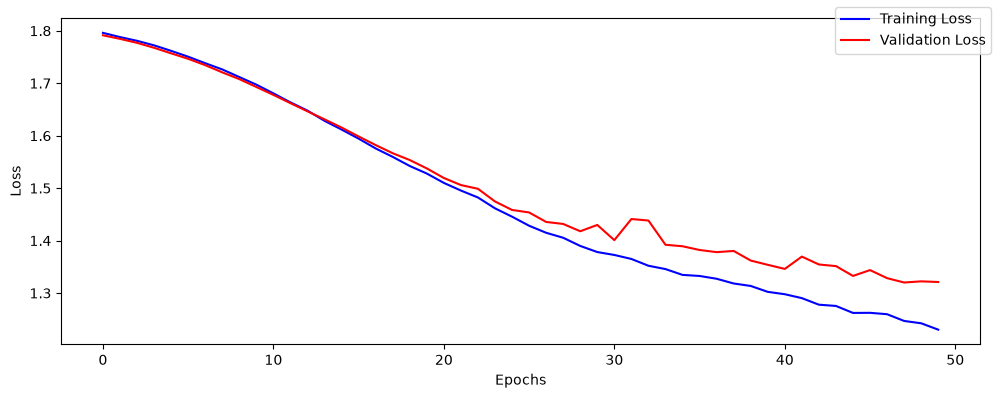

In [13]:
n_epochs = 50

mb = ModelBuilder(model, loss_fn, optimizer,print_loss_freq=5)
mb.set_loaders(train_loader, val_loader)
mb.train(n_epochs)
mb.plot_losses()

Evaluate your trained model on the test set (see `cnn_fundamentals.ipynb` for detailed steps). Calculate and print the overall accuracy of your model. If it is $0.45$ or better it is acceptable.

In [14]:
x_test = [torch.as_tensor(t[0]).unsqueeze(0) for t in list(test)]
y_test = [t[1] for t in list(test)]

test_predictions = np.array([mb.predict(i) for i in x_test]).reshape(len(test),6)
test_predictions = torch.from_numpy(test_predictions)
test_probab = nn.Softmax(dim=1)(test_predictions)
y_test_pred= torch.argmax(test_probab,dim=1)

test_correct = (y_test_pred == torch.as_tensor(y_test)).float()
accuracy = test_correct.mean()

In [15]:
print(accuracy)

tensor(0.4625)


Display the confusion matrix. If your model accuracy was around $0.45$ your normalized confusion matrix may look like:

<img align = "left" src="images/cm_first_model.png" width="50%"> 

Create your normalized confusion matrix and make sure you can comment on the outcome.

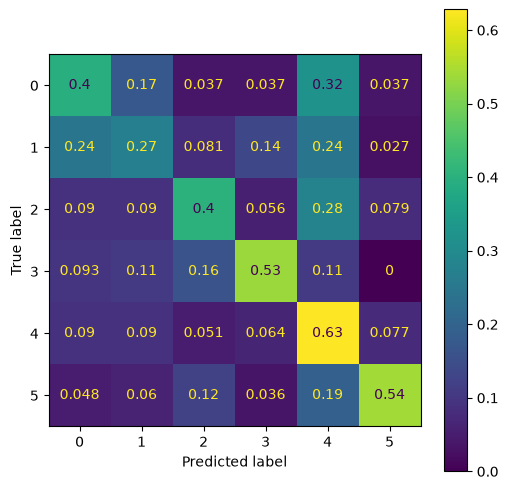

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,normalize='true',ax=ax)
plt.grid(False)

Finally, print the classification report utilizing the <code>classification_report</code> function from the <code>sklearn.metrics</code> package.

In [17]:
print(classification_report(y_test,y_test_pred))

              precision    recall  f1-score   support

           0       0.42      0.40      0.41        81
           1       0.32      0.27      0.29        74
           2       0.51      0.40      0.45        89
           3       0.61      0.53      0.57        75
           4       0.35      0.63      0.45        78
           5       0.71      0.54      0.62        83

    accuracy                           0.46       480
   macro avg       0.49      0.46      0.46       480
weighted avg       0.49      0.46      0.47       480



Questions to reflect on: 
- Is the model usable? (Better than random guessing?)
- Which objects did the model find most difficult to distinguish?
- How many times (percentage) is a golf ball misclassified as a truck?

## Create, train and evaluate a CNN to classify the images

Your model should:
- Outperform your previous model (the MLP above) by at least $10\%$
- Contain at least two convolutional layers and at least one pooling layer

In [18]:
model_cnn = nn.Sequential()
torch.manual_seed(13)
model_cnn.add_module('conv1', nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1))
model_cnn.add_module('relu1', nn.ReLU())
model_cnn.add_module('pool1', nn.MaxPool2d(kernel_size=2))
model_cnn.add_module('conv2', nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1))
model_cnn.add_module('relu2', nn.ReLU())
model_cnn.add_module('pool2', nn.MaxPool2d(kernel_size=2))
model_cnn.add_module('flatten', nn.Flatten())
model_cnn.add_module('fc1', nn.Linear(in_features=32*16*16, out_features=64))
model_cnn.add_module('relu3', nn.ReLU())
model_cnn.add_module('dropout', nn.Dropout(p=0.2))
model_cnn.add_module('fc2', nn.Linear(in_features=64, out_features=6))



Print a summary of your model.

In [19]:
summary(model_cnn, input_size=(1, 3, 65, 65),col_names=('input_size','output_size','num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 3, 65, 65]            [1, 6]                    --
├─Conv2d: 1-1                            [1, 3, 65, 65]            [1, 16, 65, 65]           448
├─ReLU: 1-2                              [1, 16, 65, 65]           [1, 16, 65, 65]           --
├─MaxPool2d: 1-3                         [1, 16, 65, 65]           [1, 16, 32, 32]           --
├─Conv2d: 1-4                            [1, 16, 32, 32]           [1, 32, 32, 32]           4,640
├─ReLU: 1-5                              [1, 32, 32, 32]           [1, 32, 32, 32]           --
├─MaxPool2d: 1-6                         [1, 32, 32, 32]           [1, 32, 16, 16]           --
├─Flatten: 1-7                           [1, 32, 16, 16]           [1, 8192]                 --
├─Linear: 1-8                            [1, 8192]                 [1, 64]                   524,352
├─ReLU: 1-9               

Train the model.

In [20]:
n_epochs = 12

optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=0.001)
mb_cnn = ModelBuilder(model_cnn, loss_fn, optimizer_cnn,print_loss_freq=2)
mb_cnn.set_loaders(train_loader, val_loader)
mb_cnn.train(n_epochs)

Epoch 2, Training loss 1.3884, Validation loss 1.2881
Epoch 4, Training loss 1.1864, Validation loss 1.1127
Epoch 6, Training loss 1.0099, Validation loss 1.0216
Epoch 8, Training loss 0.9285, Validation loss 0.9953
Epoch 10, Training loss 0.8308, Validation loss 1.0011
Epoch 12, Training loss 0.6965, Validation loss 0.9689


Plot the losses (ensure they are acceptable).

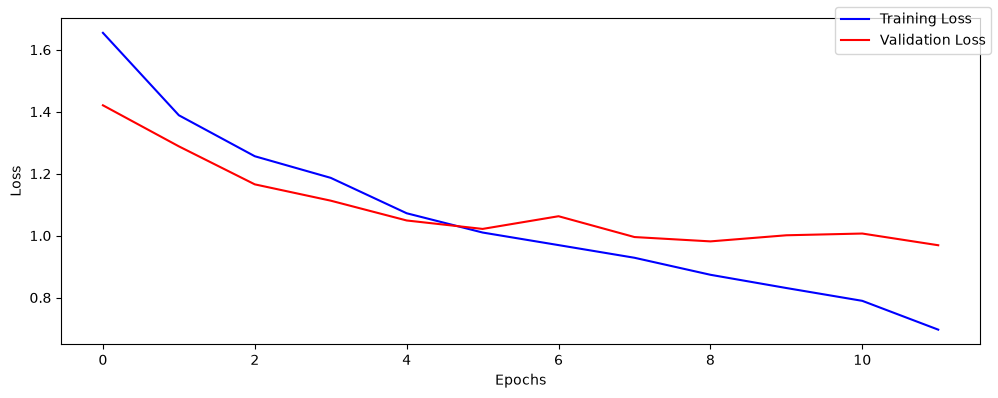

In [21]:
mb_cnn.plot_losses()

Evaluate the model on the test set. If your previous model accuracy was $0.45$ then the CNN model accuracy of at least $0.55$ is expected.

In [22]:
test_predictions = np.array([mb_cnn.predict(i) for i in x_test]).reshape(len(test),6)
test_predictions = torch.from_numpy(test_predictions)
test_probab = nn.Softmax(dim=1)(test_predictions)
y_test_pred= torch.argmax(test_probab,dim=1)

test_correct = (y_test_pred == torch.as_tensor(y_test)).float()
accuracy = test_correct.mean()
print(accuracy)

tensor(0.6250)


Print the normalized confusion matrix for the CNN model and compare it against the one from the MLP model.
Where was the biggest improvement? Which objects remained difficult to classify? 

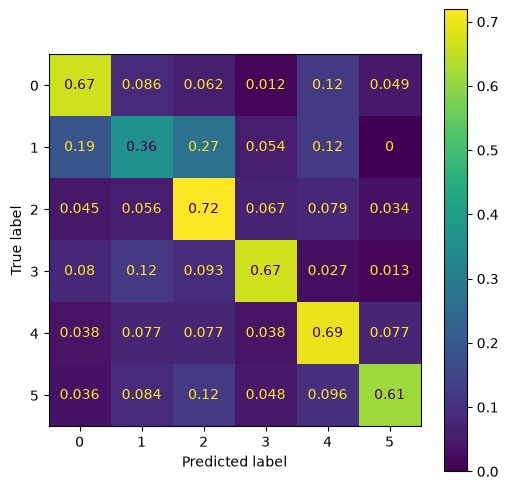

In [23]:
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test,y_test_pred,normalize='true',ax=ax)
plt.grid(False)